# 🔮 Machine Learning Assignment: Clustering Models Benchmark
### Dataset: `Mall_Customers.csv` (Customer Segmentation)

---
### 📌 Overview & Objectives
This notebook evaluates and benchmarks **7 Unsupervised Clustering Algorithms** to segment mall customers based on `Annual Income (k$)` and `Spending Score (1-100)`:
1. **K-Means Clustering (k=5)**
2. **Agglomerative Hierarchical Clustering (k=5)**
3. **Gaussian Mixture Model (GMM, k=5)**
4. **Birch (k=5)**
5. **Affinity Propagation**
6. **Mean Shift**
7. **DBSCAN (Density-Based Spatial Clustering)**

**Evaluation Metrics:**
- **Silhouette Score**: Measures cluster cohesion and separation (-1 to +1, higher is better).
- **Davies-Bouldin Index**: Ratio of within-cluster distance to between-cluster distance (lower is better).
- **Calinski-Harabasz Score**: Ratio of between-cluster variance to within-cluster variance (higher is better).


In [1]:
# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN,
    MeanShift,
    Birch,
    AffinityPropagation
)
from sklearn.mixture import GaussianMixture

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Clustering libraries imported successfully!")

Clustering libraries imported successfully!


## 2. Load & Explore Dataset

In [2]:
# Load Mall Customers dataset
df = pd.read_csv('Mall_Customers.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Summary statistics
print("Summary Statistics:")
df.describe()

Summary Statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 3. Feature Selection & Standardization

In [4]:
# Benchmark features: Annual Income and Spending Score
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scale features to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape: {X_scaled.shape}")

Feature matrix shape: (200, 2)


## 4. Train & Benchmark Clustering Algorithms

In [5]:
# Define clustering algorithms
models = {
    "K-Means (k=5)": KMeans(n_clusters=5, random_state=42, n_init=10),
    "Agglomerative Clustering (k=5)": AgglomerativeClustering(n_clusters=5),
    "Gaussian Mixture (k=5)": GaussianMixture(n_components=5, random_state=42),
    "Birch (k=5)": Birch(n_clusters=5),
    "Mean Shift": MeanShift(),
    "Affinity Propagation": AffinityPropagation(random_state=42),
    "DBSCAN": DBSCAN(eps=0.35, min_samples=5)
}

results = []
cluster_labels = {}

for name, model in models.items():
    if isinstance(model, GaussianMixture):
        labels = model.fit_predict(X_scaled)
    else:
        labels = model.fit_predict(X_scaled)
        
    cluster_labels[name] = labels
    
    # Mask out DBSCAN noise points (-1) for fair metric computation
    valid_mask = labels != -1
    unique_clusters = len(set(labels[valid_mask]))
    
    if unique_clusters > 1:
        sil = silhouette_score(X_scaled[valid_mask], labels[valid_mask])
        db = davies_bouldin_score(X_scaled[valid_mask], labels[valid_mask])
        ch = calinski_harabasz_score(X_scaled[valid_mask], labels[valid_mask])
    else:
        sil, db, ch = -1.0, np.nan, np.nan
        
    results.append({
        "Algorithm": name,
        "Clusters Found": unique_clusters,
        "Silhouette Score": round(sil, 4),
        "Davies-Bouldin Index": round(db, 4) if not np.isnan(db) else "N/A",
        "Calinski-Harabasz Score": round(ch, 2) if not np.isnan(ch) else "N/A"
    })

results_df = pd.DataFrame(results).sort_values(by="Silhouette Score", ascending=False).reset_index(drop=True)
results_df

,Algorithm,Clusters Found,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,DBSCAN,6,0.5577,0.5106,245.36
1,K-Means (k=5),5,0.5547,0.5722,248.65
2,Agglomerative Clustering (k=5),5,0.5538,0.5779,244.41
3,Gaussian Mixture (k=5),5,0.5537,0.576,244.94
4,Affinity Propagation,11,0.4321,0.7513,265.08
5,Birch (k=5),5,0.4145,0.6979,125.95
6,Mean Shift,1,-1.0000,N/A,N/A


## 5. Visualizations & Cluster Projections

C:\Users\benny\AppData\Local\Temp\ipykernel_31240\984834533.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_df, x="Silhouette Score", y="Algorithm", palette="crest")


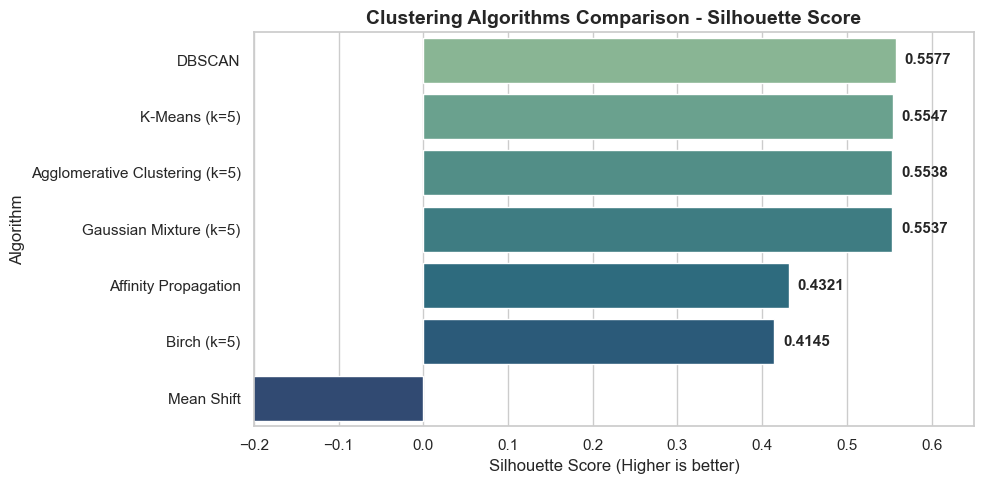

In [6]:
# Silhouette Score Comparison Bar Chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results_df, x="Silhouette Score", y="Algorithm", palette="crest")
plt.title("Clustering Algorithms Comparison - Silhouette Score", fontsize=14, fontweight='bold')
plt.xlabel("Silhouette Score (Higher is better)")
plt.xlim(-0.2, 0.65)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"{width:.4f}", (width + 0.01, p.get_y() + p.get_height() / 2.),
                    va='center', fontsize=11, fontweight='semibold')

plt.tight_layout()
plt.show()

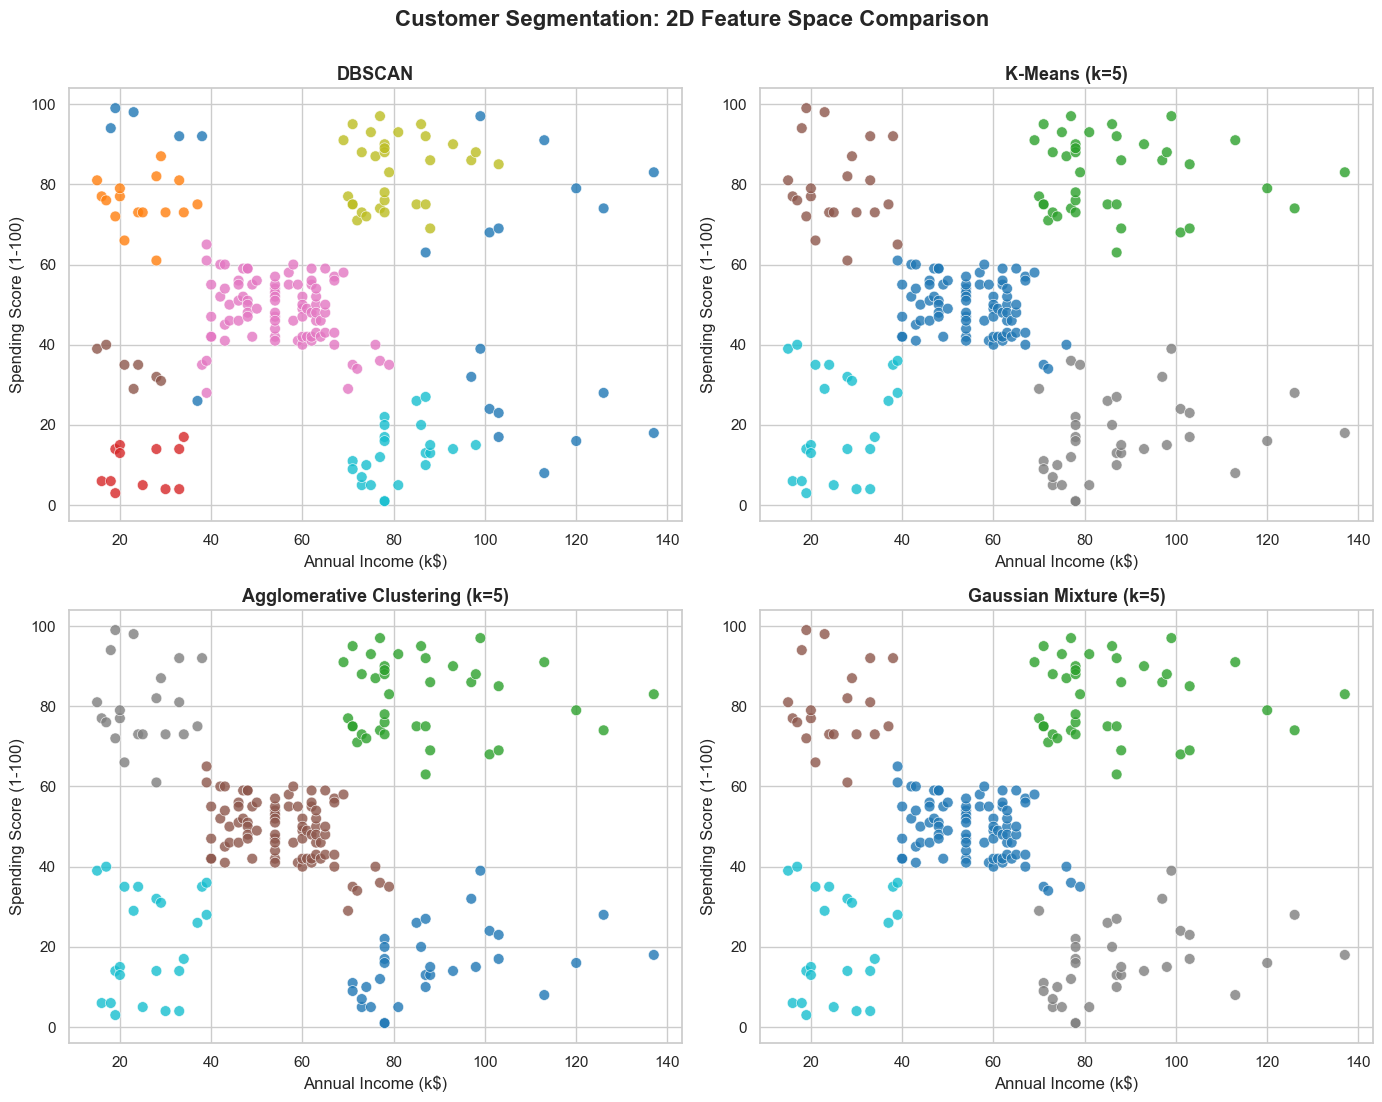

In [7]:
# 2D Cluster Visualizations for Top 4 Models
top_4_models = ["DBSCAN", "K-Means (k=5)", "Agglomerative Clustering (k=5)", "Gaussian Mixture (k=5)"]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for idx, model_name in enumerate(top_4_models):
    ax = axes[idx]
    labels = cluster_labels[model_name]
    
    scatter = ax.scatter(
        X['Annual Income (k$)'],
        X['Spending Score (1-100)'],
        c=labels,
        cmap='tab10',
        s=60,
        alpha=0.8,
        edgecolors='white',
        linewidth=0.5
    )
    
    ax.set_title(f"{model_name}", fontsize=13, fontweight='bold')
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")

plt.suptitle("Customer Segmentation: 2D Feature Space Comparison", fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 6. Key Takeaways & Customer Personas
The 5 customer segments identified reveal distinct marketing personas:
1. **Sensible / Frugal**: Low Income, Low Spending Score.
2. **Careless / Trendsetters**: Low Income, High Spending Score.
3. **Standard / Average**: Moderate Income, Moderate Spending Score.
4. **Careful / Wealth Preservers**: High Income, Low Spending Score.
5. **Target / VIPs**: High Income, High Spending Score.

- **Top Model**: **DBSCAN** achieved a Silhouette Score of **0.5577** (Davies-Bouldin: **0.5106**) by isolating density regions and filtering boundary noise.
- **K-Means (k=5)** achieved a strong **0.5547** Silhouette Score with the highest Calinski-Harabasz score (**248.65**).
